# Serverledge — Diagnostica Random Forest (paper Chen et al., UCC 2024)

**Obiettivo.** Confrontare il classificatore V2.1 addestrato con le **14 feature** realmente raccolte nella campagna schema 6 con due ablazioni (**PAPER-6** e **PAPER-5**) usando **lo stesso split, la stessa Random Forest e le stesse etichette**. Eseguiremo baseline maggioritaria, confusion matrix, analisi degli errori e controllo delle famiglie correlate.

**Chiarimento metodologico.** Il paper dichiara **21 feature per la classificazione**; la sua Tabella V riporta le **6 più importanti**, senza dichiarare che la Random Forest pubblicata sia stata addestrata su sei sole feature. Le **14 dello schema 6 sono una selezione progettuale adottata in Serverledge**, non il set ufficiale di 14 dell'articolo. PAPER-6/PAPER-5 sono **ablazioni nostre**, non riproduzioni certificate della configurazione degli autori.

**Cosa NON fa il notebook.** Non realizza i tre regressori ARM-speed del paper; non modifica il dataset, il modello `model.joblib`, i checkpoint o il codice Go. Jupyter **non cambia** l'algoritmo: il confronto serve a capire la qualità delle feature e la generalizzazione.

**Come avviarlo.** Aprire il terminale nella **radice del repository Serverledge**, con `.venv-analysis` attivo, e lanciare `python3 -m notebook`. Aprire il file nella cartella `analysis/profiling/notebooks/` e scegliere il kernel Python dell'ambiente. Il dataset completo e i risultati V2.1 devono essere già presenti nei percorsi standard.

Fonti da verificare e citare nella tesi: [paper originale](https://faculty.washington.edu/wlloyd/papers/ucc-2024-camera-ready.pdf), sezione III-C e Tabella V; [repository degli autori](https://github.com/KiritoMiao/ARM-Performance-Predection-model-artifacts).

In [1]:
from pathlib import Path
import importlib.util
import json
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.model_selection import GroupShuffleSplit
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
from sklearn.ensemble import RandomForestClassifier

ROOT = next((p for p in (Path.cwd().resolve(), *Path.cwd().resolve().parents)
             if (p / "analysis/profiling/paper_rf_classifier.py").is_file()), None)
assert ROOT is not None, "Repository serverledge non trovato negli antenati della directory del notebook"
MODULE = ROOT / "analysis/profiling/paper_rf_classifier.py"
assert MODULE.exists(), f"Apri Jupyter dalla root serverledge, file non trovato: {MODULE}"
spec = importlib.util.spec_from_file_location("paper_rf_classifier", MODULE)
rf = importlib.util.module_from_spec(spec)
spec.loader.exec_module(rf)

DATASET_DIR = ROOT / "data/profiling/gcp-paper-rf-schema6/campaign/paper_rf_schema6_final"
DATASET = DATASET_DIR / "paper-rf-dataset.csv"
ANALYSIS = ROOT / "data/profiling/gcp-paper-rf-schema6/analysis/paper-rf-classifier"
REPORT = json.loads((ANALYSIS / "evaluation.json").read_text(encoding="utf-8"))
print("Commit:", REPORT["runtime_commit"])
print("Dataset:", DATASET)
print("Accuratezza V2.1:", REPORT["evaluation"]["sample_accuracy"])

Commit: 9f9e9cfc5631b41f525f6d91fadad4415b93a8c1
Dataset: /home/ale/Documenti/GitHub/serverledge/data/profiling/gcp-paper-rf-schema6/campaign/paper_rf_schema6_final/paper-rf-dataset.csv
Accuratezza V2.1: 0.4248148148148148


## 1. Validazione e dataset di riferimento

Riutilizziamo **le medesime funzioni del classificatore già testato** per controllare manifest e SHA-256 del dataset. Usiamo solo campioni warm x86 come input; la ground truth proviene dal confronto x86/ARM effettuato nel training precedente. Il notebook non ricostruisce le etichette da zero: questo non deve essere considerato una verifica indipendente dei raw.

In [2]:
manifest = rf.verify_final_dataset(DATASET)
dataset, all14 = rf.load_dataset(DATASET)
truth = pd.read_csv(ANALYSIS / "paper_ground_truth.csv")
assert len(truth) == 67 and truth["function_name"].is_unique
assert set(truth["function_name"]) == set(dataset["function_name"])
assert truth["paper_class"].isin(rf.CLASSES).all()
ref = dataset.query("machine_tag == 'amd64'").copy()
ref = ref.merge(truth[["function_name", "paper_class"]], on="function_name", how="left", validate="many_to_one")
assert len(ref) == 6700 and ref["paper_class"].notna().all()
print("Dataset SHA:", manifest["dataset_sha256"])
print("Campioni x86:", len(ref), "| Funzioni:", ref.function_name.nunique())
display(truth["paper_class"].value_counts().rename_axis("Classe").reset_index(name="Funzioni"))

Dataset SHA: 50a7738aa1c8dd8d45abe0c89749dbc4351c6318f26cf6eafa7c4da86b61c3a5
Campioni x86: 6700 | Funzioni: 67


,Classe,Funzioni
0,ARM-similar,44
1,ARM-faster,14
2,ARM-slower,9


In [3]:
# Conteggi di integrità: 100 warm per funzione e architettura, senza cambiare l'export.
counts = dataset.groupby(["machine_tag", "function_name"]).size()
assert counts.size == 134 and counts.eq(100).all(), "Distribuzione incompleta: attesi 100 campioni per funzione/architettura"
assert len(dataset) == 13400 and dataset["request_id"].is_unique
print("PASS: 13400 righe, 67 funzioni, due architetture, 100 campioni per coppia")

PASS: 13400 righe, 67 funzioni, due architetture, 100 campioni per coppia


## 2. Origine delle feature e confronto con l'exporter

Gli autori del paper descrivono **21 feature SAAF** per i classificatori e riportano **6 feature con i maggiori valori di permutation importance** nella Tabella V. Nel dataset Serverledge schema 6 sono disponibili **14 feature**, raccolte secondo la selezione progettuale adottata prima della campagna. Il confronto qui sotto verifica solo che **i nomi** corrispondano; l'identità delle unità, della semantica e dei punti di misura deve essere verificata separatamente sul codice delle due implementazioni.

**Importante:** i confronti con PAPER-6 e PAPER-5 sono ablation study di Serverledge. Nessuno dei due equivale automaticamente al modello RF descritto nell'articolo.

In [4]:
PAPER_21 = [
    "totalMemory", "freeMemory", "pageFaults", "frameworkRuntime", "userRuntime",
    "cpuUserDelta", "cpuNiceDelta", "cpuKernelDelta", "cpuIdleDelta",
    "cpuIOWaitDelta", "cpuIrqDelta", "cpuSoftIrqDelta", "cpuStealDelta",
    "cpuGuestDelta", "cpuGuestNiceDelta", "pageFaultsDelta", "availableCPUs",
    "utilizedCPUs", "recommendedMemory", "frameworkRuntimeDeltas", "runtime"
]
PAPER_6 = [
    "pageFaultsDelta", "utilizedCPUs", "freeMemory", "cpuUserDelta",
    "cpuKernelDelta", "frameworkRuntime"
]
PAPER_5 = [x for x in PAPER_6 if x != "frameworkRuntime"]
assert len(PAPER_21) == 21 and len(all14) == 14
assert set(all14).issubset(PAPER_21)
assert set(PAPER_6).issubset(all14)
assert set(PAPER_5).issubset(all14)
feature_audit = pd.DataFrame({
    "feature_paper": PAPER_21,
    "nel_CSV_schema6": [x in all14 for x in PAPER_21],
    "in_PAPER6": [x in PAPER_6 for x in PAPER_21],
    "in_PAPER5": [x in PAPER_5 for x in PAPER_21],
})
display(feature_audit)
print("Presenti nel dataset:", len(all14), "| Non esportate:", sorted(set(PAPER_21)-set(all14)))

,feature_paper,nel_CSV_schema6,in_PAPER6,in_PAPER5
0,totalMemory,True,False,False
1,freeMemory,True,True,True
2,pageFaults,False,False,False
3,frameworkRuntime,True,True,False
4,userRuntime,True,False,False
5,cpuUserDelta,True,True,True
6,cpuNiceDelta,False,False,False
7,cpuKernelDelta,True,True,True
8,cpuIdleDelta,True,False,False
9,cpuIOWaitDelta,True,False,False


Presenti nel dataset: 14 | Non esportate: ['availableCPUs', 'cpuGuestDelta', 'cpuGuestNiceDelta', 'cpuIrqDelta', 'cpuNiceDelta', 'pageFaults', 'recommendedMemory']


## 3. Sanità delle feature (su x86)

Una feature può essere numerica e valida, ma avere varianza quasi nulla o descrivere l'ambiente anziché la funzione. L'analisi della variabilità aiuta a identificare questi casi; non dimostra causalità.

In [5]:
statistics = ref[all14].agg(["min", "median", "max", "std"]).T
statistics["valori_distinti"] = ref[all14].nunique()
statistics["frazione_zeri"] = (ref[all14] == 0).mean()
display(statistics.sort_values("valori_distinti"))
print("Numero di feature costanti:", int((statistics["valori_distinti"] <= 1).sum()))

,min,median,max,std,valori_distinti,frazione_zeri
cpuStealDelta,0.000000e+00,0.000000e+00,0.000000e+00,0.000000,1,1.000000
totalMemory,1.636926e+07,1.637127e+07,1.637127e+07,983.788500,2,0.000000
cpuSoftIrqDelta,0.000000e+00,0.000000e+00,8.300000e+02,34.413139,29,0.668806
cpuIOWaitDelta,0.000000e+00,0.000000e+00,6.390000e+03,189.713252,64,0.870149
cpuKernelDelta,0.000000e+00,3.000000e+01,3.647000e+04,3104.399474,254,0.115522
utilizedCPUs,5.800000e-02,1.007000e+00,2.007000e+00,0.127615,533,0.000000
cpuUserDelta,0.000000e+00,1.220000e+03,5.044000e+04,9690.308779,928,0.002537
cpuIdleDelta,1.400000e+02,4.130000e+03,1.508700e+05,31712.733385,1736,0.000000
pageFaultsDelta,0.000000e+00,1.994000e+03,3.869023e+06,261855.781513,3569,0.001045
freeMemory,1.220989e+07,1.393166e+07,1.520444e+07,788766.170271,4673,0.000000


Numero di feature costanti: 1


## 4. Riprodurre esattamente lo split della V2.1

Applichiamo `GroupShuffleSplit(test_size=7/18, random_state=42)` e la funzione `family()` dello script V2.1 (normalizza il prefisso `twin-`). Lo split resta uguale per i tre esperimenti. Verifichiamo esplicitamente anche l'elenco delle funzioni test contro `evaluation.json`: se cambia, il notebook si ferma invece di confrontare numeri non equivalenti.

In [6]:
SEED = 42
Y = ref["paper_class"].to_numpy()
G = ref["function_name"].astype(str).map(rf.family).to_numpy()
train_idx, test_idx = next(GroupShuffleSplit(n_splits=1, test_size=7/18, random_state=SEED).split(ref[all14], Y, G))
train_functions = set(ref.iloc[train_idx]["function_name"])
test_functions = set(ref.iloc[test_idx]["function_name"])
print(f"Funzioni train/test: {len(train_functions)} / {len(test_functions)}")
print("Famiglie disgiunte:", set(G[train_idx]).isdisjoint(set(G[test_idx])))
assert set(G[train_idx]).isdisjoint(set(G[test_idx]))
assert len(test_functions) == REPORT["evaluation"]["test_functions"] == 27
assert set(test_functions) == set(REPORT["evaluation"]["splits"][0]["test_functions"])

Funzioni train/test: 40 / 27
Famiglie disgiunte: True


## 5. Baseline maggioritaria calcolata **sullo stesso test**

La baseline predice sempre la classe prevalente nel training (non nella totalità del dataset): così la valutazione è corretta anche se le classi del test differiscono da quelle globali.

In [7]:
majority_train = ref.iloc[train_idx]["paper_class"].value_counts().idxmax()
test_truth = ref.iloc[test_idx]["paper_class"]
base_sample = float((test_truth == majority_train).mean())
base_function = float((ref.iloc[test_idx].groupby("function_name")["paper_class"].first() == majority_train).mean())
print("Classe maggioritaria TRAIN:", majority_train)
print(f"Baseline campioni TEST: {base_sample:.2%}")
print(f"Baseline funzioni TEST: {base_function:.2%}")

Classe maggioritaria TRAIN: ARM-similar
Baseline campioni TEST: 59.26%
Baseline funzioni TEST: 59.26%


## 6. Addestramento controllato: 14 vs 6 vs 5 feature

**Stesso modello:** `RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1)`, senza bilanciamento/tuning; **stesso split e stessa ground truth**. La modifica riguarda solo le feature. Non viene sovrascritto `model.joblib`.

In [8]:
SETS = {"Schema6_14": all14, "PAPER_6_ablation": PAPER_6, "PAPER_5_ablation": PAPER_5}
experiments = {}
summary_rows = []
for tag, selected in SETS.items():
    model = RandomForestClassifier(n_estimators=100, random_state=SEED, n_jobs=-1)
    model.fit(ref.iloc[train_idx][selected].to_numpy(dtype=float), Y[train_idx])
    preds = model.predict(ref.iloc[test_idx][selected].to_numpy(dtype=float))
    heldout = ref.iloc[test_idx][["function_name", "paper_class"]].copy()
    heldout["prediction"] = preds
    votes = {}
    for n in (1,10,100):
        decisions = []
        for fn, group in heldout.groupby("function_name", sort=True):
            if len(group) >= n:
                vote = rf.majority(group["prediction"].iloc[:n].tolist())
                decisions.append(vote == group["paper_class"].iloc[0])
        votes[n] = float(np.mean(decisions))
    metrics = {
        "feature_set": tag,
        "n_feature": len(selected),
        "accuracy_samples": float(accuracy_score(Y[test_idx], preds)),
        "macro_F1": classification_report(Y[test_idx], preds, labels=list(rf.CLASSES), output_dict=True, zero_division=0)["macro avg"]["f1-score"],
        "vote_1": votes[1], "vote_10": votes[10], "vote_100": votes[100],
    }
    summary_rows.append(metrics)
    experiments[tag] = {"model": model, "columns": selected, "pred": preds, "heldout": heldout}
results = pd.DataFrame(summary_rows).set_index("feature_set")
display(results.style.format({k:"{:.2%}" for k in ["accuracy_samples","macro_F1","vote_1","vote_10","vote_100"]}))
old = REPORT["evaluation"]["sample_accuracy"]
assert abs(results.loc["Schema6_14","accuracy_samples"] - old) < 1e-12, "La replica 14 feature non coincide con il modello V2.1: verificare versioni e ordine dei dati."
print("PASS: la colonna 14 feature riproduce esattamente l'accuratezza originale:", old)

,n_feature,accuracy_samples,macro_F1,vote_1,vote_10,vote_100
feature_set,,,,,,
Schema6_14,14,42.48%,22.81%,37.04%,44.44%,40.74%
PAPER_6_ablation,6,42.04%,23.93%,40.74%,48.15%,40.74%
PAPER_5_ablation,5,45.59%,28.16%,44.44%,51.85%,44.44%


PASS: la colonna 14 feature riproduce esattamente l'accuratezza originale: 0.4248148148148148


## 7. Confusion matrix e richiamo per classe

Guardiamo separatamente `ARM-faster`, `ARM-slower` e `ARM-similar`. Un'elevata accuratezza globale non basta se il modello sbaglia quasi tutte le funzioni realmente più lente su ARM.

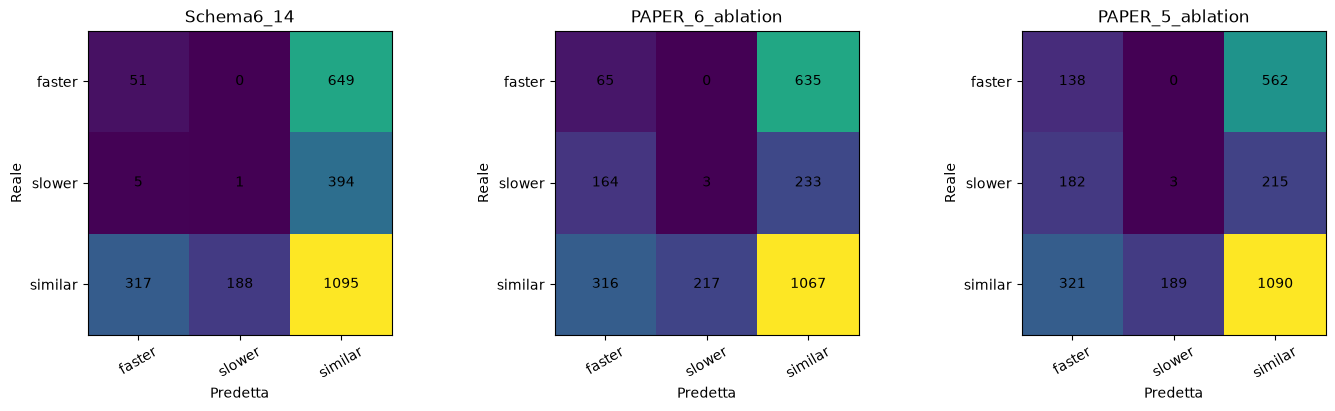

=== Schema6_14 ===


,precision,recall,f1-score,support
ARM-faster,0.136729,0.072857,0.095061,700.000000
ARM-slower,0.005291,0.002500,0.003396,400.000000
ARM-similar,0.512161,0.684375,0.585875,1600.000000
accuracy,0.424815,0.424815,0.424815,0.424815
macro avg,0.218060,0.253244,0.228110,2700.000000
weighted avg,0.339735,0.424815,0.372333,2700.000000


=== PAPER_6_ablation ===


,precision,recall,f1-score,support
ARM-faster,0.119266,0.092857,0.104418,700.00000
ARM-slower,0.013636,0.007500,0.009677,400.00000
ARM-similar,0.551421,0.666875,0.603678,1600.00000
accuracy,0.420370,0.420370,0.420370,0.42037
macro avg,0.228108,0.255744,0.239258,2700.00000
weighted avg,0.359709,0.420370,0.386240,2700.00000


=== PAPER_5_ablation ===


,precision,recall,f1-score,support
ARM-faster,0.215289,0.197143,0.205817,700.000000
ARM-slower,0.015625,0.007500,0.010135,400.000000
ARM-similar,0.583824,0.681250,0.628786,1600.000000
accuracy,0.455926,0.455926,0.455926,0.455926
macro avg,0.271579,0.295298,0.281579,2700.000000
weighted avg,0.404100,0.455926,0.427475,2700.000000


In [9]:
fig, axes = plt.subplots(1, 3, figsize=(14,4), constrained_layout=True)
for ax, (tag, details) in zip(axes, experiments.items()):
    mat = confusion_matrix(Y[test_idx], details["pred"], labels=list(rf.CLASSES))
    im = ax.imshow(mat)
    for (i,j),val in np.ndenumerate(mat): ax.text(j,i,str(val),ha="center",va="center")
    ax.set_xticks(range(3), ["faster","slower","similar"], rotation=30)
    ax.set_yticks(range(3), ["faster","slower","similar"])
    ax.set_xlabel("Predetta"); ax.set_ylabel("Reale")
    ax.set_title(tag)
plt.show()
for tag, details in experiments.items():
    print("===",tag,"===")
    display(pd.DataFrame(classification_report(Y[test_idx], details["pred"], labels=list(rf.CLASSES), output_dict=True, zero_division=0)).T)

## 8. Quali funzioni sbagliamo?

Il voto su 100 campioni mostra gli errori **sistematici per funzione**, anche quando i singoli campioni non sono tutti sbagliati.

In [10]:
for tag, details in experiments.items():
    rows=[]
    for fn, g in details["heldout"].groupby("function_name", sort=True):
        predicted = rf.majority(g["prediction"].tolist())
        rows.append({"function_name":fn,"true":g["paper_class"].iloc[0], "vote100":predicted, "correct": predicted == g["paper_class"].iloc[0]})
    per_fn = pd.DataFrame(rows)
    print(tag, "— errate", (~per_fn["correct"]).sum(), "su", len(per_fn))
    display(per_fn.loc[~per_fn["correct"]])

Schema6_14 — errate 16 su 27


,function_name,true,vote100,correct
0,amd_faster,ARM-slower,ARM-similar,False
1,base64stream-py,ARM-similar,ARM-faster,False
3,billibench-knn,ARM-faster,ARM-similar,False
10,filehandle,ARM-faster,ARM-similar,False
11,float-ops-py,ARM-similar,ARM-faster,False
12,functionbench-random-disk-io,ARM-similar,ARM-faster,False
13,graph-pagerank,ARM-slower,ARM-similar,False
14,graph-pagerank-node,ARM-slower,ARM-similar,False
16,jsonparse,ARM-similar,ARM-slower,False
17,memory-rw-node,ARM-similar,ARM-slower,False


PAPER_6_ablation — errate 16 su 27


,function_name,true,vote100,correct
0,amd_faster,ARM-slower,ARM-similar,False
1,base64stream-py,ARM-similar,ARM-faster,False
3,billibench-knn,ARM-faster,ARM-similar,False
10,filehandle,ARM-faster,ARM-similar,False
11,float-ops-py,ARM-similar,ARM-faster,False
12,functionbench-random-disk-io,ARM-similar,ARM-faster,False
13,graph-pagerank,ARM-slower,ARM-faster,False
14,graph-pagerank-node,ARM-slower,ARM-faster,False
15,hashing,ARM-faster,ARM-similar,False
16,jsonparse,ARM-similar,ARM-slower,False


PAPER_5_ablation — errate 15 su 27


,function_name,true,vote100,correct
0,amd_faster,ARM-slower,ARM-similar,False
1,base64stream-py,ARM-similar,ARM-faster,False
3,billibench-knn,ARM-faster,ARM-similar,False
10,filehandle,ARM-faster,ARM-similar,False
11,float-ops-py,ARM-similar,ARM-faster,False
12,functionbench-random-disk-io,ARM-similar,ARM-faster,False
13,graph-pagerank,ARM-slower,ARM-faster,False
14,graph-pagerank-node,ARM-slower,ARM-faster,False
15,hashing,ARM-faster,ARM-similar,False
16,jsonparse,ARM-similar,ARM-slower,False


## 9. Verifica di possibili famiglie semanticamente correlate tra train e test

Nel codice V2.1 la funzione `family()` elimina soltanto `twin-`. Varianti `-py` e `-node` dello stesso workload possono quindi finire in partizioni diverse. Il controllo sotto **non invalida automaticamente lo split**, ma elenca coppie potenzialmente correlate che meritano una valutazione metodologica. Non cambiamo il risultato principale.

In [11]:
def semantic_family(name):
    name = rf.family(str(name))
    name = re.sub(r"-(py|node)$", "", name)
    return re.sub(r"[^a-z0-9]+", "", name.lower())
train_map = {}
for x in sorted(train_functions): train_map.setdefault(semantic_family(x), []).append(x)
test_map = {}
for x in sorted(test_functions): test_map.setdefault(semantic_family(x), []).append(x)
shared_semantics = sorted(set(train_map).intersection(test_map))
display(pd.DataFrame([{"famiglia_normalizzata":g,"train":", ".join(train_map[g]),"test":", ".join(test_map[g])} for g in shared_semantics]))
print("Gruppi potenzialmente correlati a cavallo del train/test:",len(shared_semantics))

,famiglia_normalizzata,train,test
0,base64stream,base64stream,base64stream-py
1,compression,"compression-node, compression-py",compression
2,dynamichtml,"dynamic-html-node, dynamic-html-py",dynamichtml
3,floatops,float-ops-node,float-ops-py
4,graphpagerank,graph-pagerank-py,"graph-pagerank, graph-pagerank-node"
5,hashing,hashing-py,hashing
6,jsonparse,jsonparse-py,jsonparse
7,memoryrw,memory-rw-py,memory-rw-node
8,pointerchase,pointerchase-py,pointerchase
9,randomaccess,randomaccess-py,randomaccess


Gruppi potenzialmente correlati a cavallo del train/test: 11


## 10. Sensibilità: split più severo (soltanto le 14 feature)

**Analisi aggiuntiva, non replica del protocollo V2.1:** raggruppiamo anche varianti `-py` / `-node` e normalizziamo i separatori. Lo scopo è vedere quanto la valutazione dipenda dalla definizione di *funzione mai vista*. Non usiamo questo risultato per fare tuning degli iperparametri.

In [12]:
strict = ref["function_name"].map(semantic_family).to_numpy()
tr2, te2 = next(GroupShuffleSplit(n_splits=1,test_size=7/18,random_state=SEED).split(ref[all14], Y, strict))
assert set(strict[tr2]).isdisjoint(set(strict[te2]))
strict_model = RandomForestClassifier(n_estimators=100,random_state=SEED,n_jobs=-1)
strict_model.fit(ref.iloc[tr2][all14].to_numpy(),Y[tr2])
strict_pred = strict_model.predict(ref.iloc[te2][all14].to_numpy())
print("Funzioni test (split rigido):",ref.iloc[te2].function_name.nunique())
print("Accuracy campione (split rigido):",round(accuracy_score(Y[te2],strict_pred),4))
print("Baseline maggioritaria test (train-majority):",round(np.mean(Y[te2] == pd.Series(Y[tr2]).value_counts().idxmax()),4))
display(pd.DataFrame(confusion_matrix(Y[te2],strict_pred,labels=list(rf.CLASSES)),index=rf.CLASSES,columns=rf.CLASSES))

Funzioni test (split rigido): 26
Accuracy campione (split rigido): 0.5612
Baseline maggioritaria test (train-majority): 0.6538


,ARM-faster,ARM-slower,ARM-similar
ARM-faster,185,0,415
ARM-slower,0,1,299
ARM-similar,327,100,1273


## 11. Sensibilità delle etichette alla soglia del 15%

Non cambiamo la soglia nel training principale. Contiamo soltanto le funzioni il cui delta reale è vicino a ±15 punti percentuali: piccole variazioni delle misure potrebbero spostarle tra classi.

In [13]:
deltas = pd.to_numeric(truth["delta_percent"])
distance_to_boundary = np.minimum(np.abs(deltas-15),np.abs(deltas+15))
boundary = truth.assign(distance_from_boundary_pp=distance_to_boundary)
display(boundary.sort_values("distance_from_boundary_pp").head(15))
for margin in (1,3,5):
    print(f"Funzioni entro {margin} punti percentuali da una soglia: {int((distance_to_boundary <= margin).sum())} / 67")

,function_name,x86_median_duration_ms,arm_median_duration_ms,delta_percent,paper_class,serverledge_class,distance_from_boundary_pp
52,readdisk,1223.756193,1043.330925,-14.743563,ARM-similar,architecture-independent,0.256437
53,readmemory,12170.452969,10380.960477,-14.703582,ARM-similar,architecture-independent,0.296418
17,filehandle,36653.482773,30821.156024,-15.912067,ARM-faster,arm-preferred,0.912067
26,functionbench-sequential-disk-io,557.271973,646.008131,15.923312,ARM-slower,x86-preferred,0.923312
58,thread,28222.502795,23684.381381,-16.079798,ARM-faster,arm-preferred,1.079798
16,dynamichtml,852.896811,971.244509,13.875969,ARM-similar,architecture-independent,1.124031
6,billibench-linear-regression,1115.999138,967.596114,-13.297772,ARM-similar,architecture-independent,1.702228
1,arm_faster,868.131044,722.812795,-16.739207,ARM-faster,arm-preferred,1.739207
20,functionbench-dd,113.777902,94.675231,-16.789439,ARM-faster,arm-preferred,1.789439
45,memory-rw-py,5973.088536,6727.171705,12.624678,ARM-similar,architecture-independent,2.375322


Funzioni entro 1 punti percentuali da una soglia: 4 / 67
Funzioni entro 3 punti percentuali da una soglia: 12 / 67
Funzioni entro 5 punti percentuali da una soglia: 17 / 67


## 12. Interpretazione

1. **Riproducibilità:** la riga `Schema6_14` deve coincidere esattamente con il 42,48148% del V2.1. In caso contrario fermarsi e verificare versioni, ordine dei campioni e split.
2. **Ablation delle feature:** PAPER-6 e PAPER-5 aiutano a valutare se una rappresentazione più compatta predice meglio, ma una differenza osservata su un solo split non è ancora una prova stabile.
3. **Baseline e recall:** confrontare sempre ciascun risultato con la baseline maggioritaria dello **stesso test** e controllare la classe `ARM-slower`.
4. **Leakage per varianti:** verificare i workload semanticamente correlati su train/test e leggere lo split rigido come *analisi di sensibilità*, non come risultato paper-faithful.
5. **Limite metodologico:** 100 osservazioni della stessa funzione non equivalgono a 100 funzioni indipendenti. Il numero di unità indipendenti per la generalizzazione è quello delle **funzioni/gruppi**.
6. **Futuro:** per attribuire causalità al basso risultato servono confronti controllati e, se necessario, audit dell'equivalenza semantica delle metriche con SAAF e del codice originale degli autori.

**Uso corretto dei risultati.** Il 93,35% riferito nel paper è il risultato della loro pipeline, con dataset, feature e protocollo propri; non va confrontato come se fosse lo stesso esperimento. Il risultato del notebook chiarisce se l'ablazione delle feature aiuta **sul nostro split**; non dimostra quale insieme sia universalmente migliore. Il modello finale `.joblib` della V2.1 rimane intatto.

## 13. Audit raw JSONL: controllare le invocazioni warm, non soltanto la prima riga

La prima riga di ogni blocco può essere il **cold start**: in questo caso `node_environment` e `profile` sono omessi. Il controllo cerca le invocazioni *warm* con `eligibility.resource_clustering = true` e verifica che i campi necessari per le sette dimensioni mancanti siano realmente nei raw. **La loro presenza non garantisce automaticamente identità semantica con SAAF**, in particolare per `recommendedMemory` e `pageFaults`.

Il codice non modifica il dataset né gli artefatti di training.

In [14]:
import json
RAW_EXAMPLE = DATASET_DIR / "blocks/amd64/round_000/base64stream/raw.jsonl"
with RAW_EXAMPLE.open(encoding="utf-8") as f:
    raw_records = [json.loads(line) for line in f if line.strip()]
warmed = [r for r in raw_records if r.get("warm_start") is True and
          r.get("eligibility", {}).get("resource_clustering") is True]
print("Record totali:", len(raw_records))
print("Prima riga: warm_start=", raw_records[0].get("warm_start"),
      "profile presente=", "profile" in raw_records[0],
      "node_environment presente=", "node_environment" in raw_records[0])
print("Record warm validi:", len(warmed))
assert warmed, "Nessun campione warm eleggibile nel raw di esempio"
raw_sources = {
    "pageFaults": ("node_environment", "page_faults_before"),
    "cpuNiceDelta": ("node_environment", "cpu_nice_delta_ticks"),
    "cpuIrqDelta": ("node_environment", "cpu_irq_delta_ticks"),
    "cpuGuestDelta": ("node_environment", "cpu_guest_delta_ticks"),
    "cpuGuestNiceDelta": ("node_environment", "cpu_guest_nice_delta_ticks"),
    "availableCPUs": ("node_environment", "available_cpus"),
    "recommendedMemory (candidato, verificare semantica)": ("function_configuration", "configured_memory_mb"),
}
for label, (section, key) in raw_sources.items():
    valid = sum(key in (r.get(section) or {}) for r in warmed)
    print(f"{label}: {valid}/{len(warmed)} record warm contengono {section}.{key}")
clk = [r.get("node_environment", {}).get("cpu_clock_ticks_per_second")
       for r in warmed]
print("CLK_TCK disponibile su warm:", sum(isinstance(x, (int,float)) and x > 0 for x in clk), "/", len(clk))
print("\nCampi node_environment di una warm valida:")
print(sorted((warmed[0].get("node_environment") or {}).keys()))


Record totali: 21
Prima riga: warm_start= False profile presente= False node_environment presente= False
Record warm validi: 20
pageFaults: 20/20 record warm contengono node_environment.page_faults_before
cpuNiceDelta: 20/20 record warm contengono node_environment.cpu_nice_delta_ticks
cpuIrqDelta: 20/20 record warm contengono node_environment.cpu_irq_delta_ticks
cpuGuestDelta: 20/20 record warm contengono node_environment.cpu_guest_delta_ticks
cpuGuestNiceDelta: 20/20 record warm contengono node_environment.cpu_guest_nice_delta_ticks
availableCPUs: 20/20 record warm contengono node_environment.available_cpus
recommendedMemory (candidato, verificare semantica): 20/20 record warm contengono function_configuration.configured_memory_mb
CLK_TCK disponibile su warm: 20 / 20

Campi node_environment di una warm valida:
['available_cpus', 'collected', 'complete', 'cpu_available', 'cpu_clock_ticks_available', 'cpu_clock_ticks_per_second', 'cpu_guest_delta_ms', 'cpu_guest_delta_ticks', 'cpu_guest

## 14. Stratified 5-fold **group** cross-validation (diagnostica, non tuning)

Ogni funzione viene utilizzata in training in quattro fold e in test in uno solo. I gruppi sono costruiti con la funzione `semantic_family` già definita sopra: le versioni `-py`, `-node` e `twin-` dello stesso workload non possono finire contemporaneamente in training e test. **Non equivale ad aggiungere nuove funzioni al dataset**, ma rende meno dipendente l'analisi da un singolo holdout.

Con 9 funzioni ARM-slower su 67 il bilanciamento fra fold può restare imperfetto: perciò mostriamo anche la composizione dei fold, una baseline maggioritaria definita sui soli training fold, il macro-F1 e il recall per classe. Non cambiamo il `model.joblib` finale del classificatore V2.1.

In [15]:
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.metrics import f1_score, recall_score

cv_groups = ref["function_name"].astype(str).map(semantic_family).to_numpy()
cv_y = ref["paper_class"].to_numpy()
cv = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=42)
folds = list(cv.split(ref[all14], cv_y, groups=cv_groups))

fold_audit = []
for fnum, (tr, te) in enumerate(folds, start=1):
    assert set(cv_groups[tr]).isdisjoint(set(cv_groups[te]))
    classes_test = ref.iloc[te].groupby("function_name")["paper_class"].first().value_counts()
    fold_audit.append({"fold": fnum, "funzioni_train": ref.iloc[tr].function_name.nunique(),
                       "funzioni_test": ref.iloc[te].function_name.nunique(),
                       **{c: int(classes_test.get(c,0)) for c in rf.CLASSES}})
print("Distribuzione delle classi per funzione nei fold (non per campione):")
display(pd.DataFrame(fold_audit))

cv_summary = []
for label, selected in SETS.items():
    out_of_fold = np.empty(len(ref), dtype=object)
    majority_oof = np.empty(len(ref), dtype=object)
    for tr, te in folds:
        clf = RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1)
        clf.fit(ref.iloc[tr][selected].to_numpy(dtype=float), cv_y[tr])
        out_of_fold[te] = clf.predict(ref.iloc[te][selected].to_numpy(dtype=float))
        majority = pd.Series(cv_y[tr]).value_counts().idxmax()
        majority_oof[te] = majority
    assert all(isinstance(p, str) for p in out_of_fold)
    fn = ref[["function_name","paper_class"]].copy()
    fn["predicted"] = out_of_fold
    decisions = []
    for name, group in fn.groupby("function_name", sort=True):
        decisions.append({"function": name, "true":group.paper_class.iloc[0],
                          "vote10": rf.majority(group.predicted.iloc[:10].tolist()),
                          "vote100": rf.majority(group.predicted.tolist())})
    per_function = pd.DataFrame(decisions)
    recalls = recall_score(cv_y, out_of_fold, labels=list(rf.CLASSES), average=None, zero_division=0)
    cv_summary.append({"feature_set": label,
                       "accuracy_5fold": accuracy_score(cv_y, out_of_fold),
                       "macroF1_5fold": f1_score(cv_y, out_of_fold, labels=list(rf.CLASSES), average="macro", zero_division=0),
                       "baseline_5fold": accuracy_score(cv_y, majority_oof),
                       "vote10_5fold": np.mean(per_function.vote10 == per_function.true),
                       "vote100_5fold": np.mean(per_function.vote100 == per_function.true),
                       **{f"recall_{c}": v for c,v in zip(rf.CLASSES, recalls)}})
cv_df = pd.DataFrame(cv_summary).set_index("feature_set")
display(cv_df.style.format("{:.2%}"))
print("Nota: la cross-validation è diagnostica; non è il training del modello finale già salvato.")


Distribuzione delle classi per funzione nei fold (non per campione):


,fold,funzioni_train,funzioni_test,ARM-faster,ARM-slower,ARM-similar
0,1,53,14,3,2,9
1,2,54,13,3,1,9
2,3,54,13,3,2,8
3,4,53,14,3,2,9
4,5,54,13,2,2,9


,accuracy_5fold,macroF1_5fold,baseline_5fold,vote10_5fold,vote100_5fold,recall_ARM-faster,recall_ARM-slower,recall_ARM-similar
feature_set,,,,,,,,
Schema6_14,46.31%,32.92%,65.67%,44.78%,46.27%,6.43%,30.67%,62.20%
PAPER_6_ablation,52.42%,38.93%,65.67%,50.75%,52.24%,15.79%,30.78%,68.50%
PAPER_5_ablation,50.72%,39.33%,65.67%,49.25%,49.25%,19.64%,32.89%,64.25%


Nota: la cross-validation è diagnostica; non è il training del modello finale già salvato.
